# Statistics
- In the realm of data science, statistics is the scientific discipline that involves collecting, organizing, analyzing, interpreting, and presenting data.

### Descriptive Statistics
- Descriptive statistics are methods used to describe and summarize the features of a dataset. They help in understanding the main characteristics of the data.
- The describe data e.g mean, median, mode, min, max, standard deviation, variance, and etc
- Suppose you have a dataset containing the ages of individuals in a population. You calculate the mean age, which gives you the average age of the population. Additionally, you calculate the standard deviation, which provides a measure of the spread or variability of ages around the mean. These descriptive statistics offer insights into the central tendency (mean) and the diversity (standard deviation) of ages within the population.

### Inferential statistics
- Inferential statistics are methods used to draw conclusions or make predictions about a population based on a sample from that population.
- That we do some conclusion using the statistical tests.
- **For example:** Let's say you want to test whether a new drug improves the recovery time for a specific illness. You take a sample of patients and administer the drug to them, then compare their recovery times to those who didn't receive the drug. Using a t-test, you analyze the data to determine if the observed differences in recovery times between the two groups are statistically significant. This helps in inferring whether the drug indeed has an effect on recovery time for the entire population.

# Descriptive Statistics
- Statistics that summarize data such as mean, median, mode, standard deviation, variance, and etc.

# Central tendency
- What is the typical value?
- Where is the center of data?
- They can be assesed by mean, median and mode.

- **Mean**: Average value. Calculated by summing all the data points and dividin by the total number of points.
- **Median**: The middle value of the dataset.
- **Mode**: The most frequent value of the dataset.

# Outliers
- Outliers are data points that significantly differ from other observations in a dataset. They can either be unusually high or low compared to the majority of the data points. Outliers can occur due to measurement errors, variability in the data, or represent true but rare occurrences within the population being studied.
- The effect of outliers on the mean, which is a measure of central tendency, can be substantial. Outliers can skew the mean by pulling its value towards the extreme end where the outlier lies.
- **How do we know what a substantial difference is? A data point is an outlier if:**
- **data < Q1 - 1.5 x IQR or**
- **data > Q3 - 1.5 x IQR**

In [ ]:
# importing pandas
import pandas as pd

In [ ]:
# loading dataset
df = pd.read_csv("/content/heart_dataset_practice.csv")

In [ ]:
# checking the data
df.head()

,Unnamed: 0,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [ ]:
# studying resting blood pressure
df["RestingBP"].mean()

132.39651416122004

In [ ]:
df["RestingBP"].median()

130.0

In [ ]:
df["RestingBP"].mode()

0    120
Name: RestingBP, dtype: int64

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

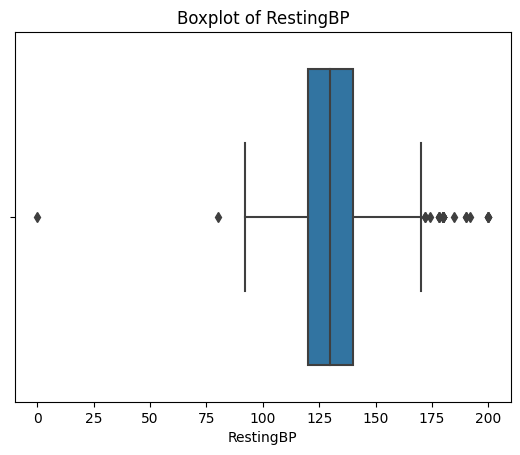

In [ ]:
sns.boxplot(x=df["RestingBP"])
plt.title("Boxplot of RestingBP")
plt.show()

In [ ]:
clean_rbp = df[(df["RestingBP"] <1) | (df["RestingBP"] <175)]

In [ ]:
clean_rbp["RestingBP"].mean()

131.0491620111732

In [ ]:
clean_rbp["RestingBP"].std()

16.656479108048465

In [ ]:
# clean resting bp data using IQR method
q3 = df["RestingBP"].quantile(0.75)
q1 = df["RestingBP"].quantile(0.25)
iqr = q3 - q1
upper_range = q3 + (1.5 * iqr)
lower_range = q1 - (1.5 * iqr)
clean_rbp_iqr = df[(df["RestingBP"] >= lower_range) & (df["RestingBP"] <= upper_range)]

In [ ]:
clean_rbp_iqr["RestingBP"].mean()

131.1134831460674

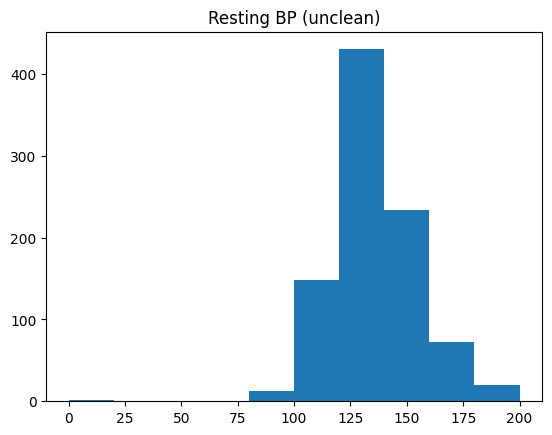

In [ ]:
plt.hist(df["RestingBP"])
plt.title("Resting BP (unclean)")
plt.show()

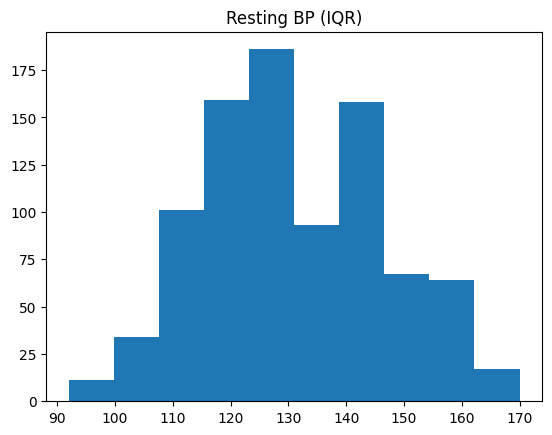

In [ ]:
plt.hist(clean_rbp_iqr["RestingBP"])
plt.title("Resting BP (clean)")
plt.show()

<ipython-input-38-726037ab2451>:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["RestingBP"])


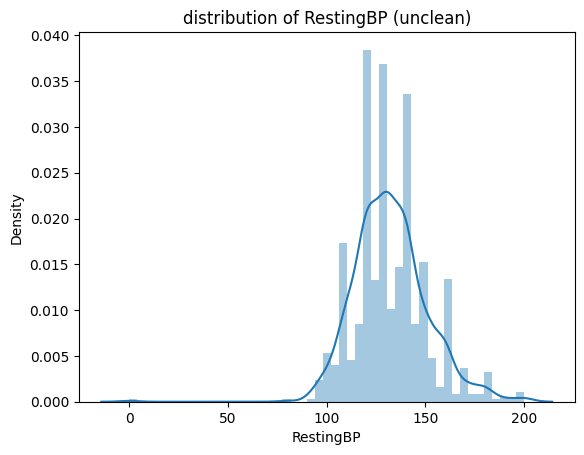

In [ ]:
sns.distplot(df["RestingBP"])
plt.title("distribution of RestingBP (unclean)")
plt.show()

<ipython-input-39-d8cdc295c00d>:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(clean_rbp_iqr["RestingBP"])


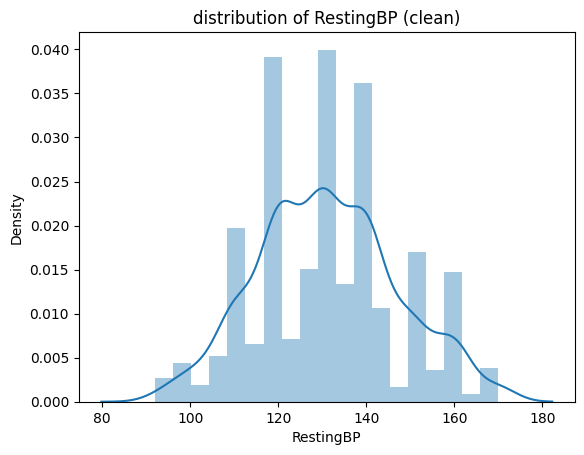

In [ ]:
sns.distplot(clean_rbp_iqr["RestingBP"])
plt.title("distribution of RestingBP (clean)")
plt.show()

### Variance:
Variance is a statistical measure that quantifies the amount of dispersion or spread in a set of data points. It calculates the average of the squared differences from the mean. In simpler terms, it measures how far each number in a dataset is from the mean and then squares the result to give emphasis to larger differences. The variance is denoted by σ^2 (population variance) or s^2 (sample variance), where σ represents the standard deviation of the population and s represents the standard deviation of the sample.


### Standard Deviation:
Standard deviation is another measure of the amount of variation or dispersion in a set of values. It is the square root of the variance. Essentially, it represents the average distance of data points from the mean. The standard deviation provides a measure of how spread out the values in a dataset are. A smaller standard deviation indicates that the data points tend to be close to the mean, while a larger standard deviation indicates that they are spread out over a wider range.



In [ ]:
# variance
# variance tells us on an average how each much each value is far from the mean or average value
df["RestingBP"].var()

342.77390277569896

In [ ]:
# standard deviation
# standard deviation tells us average error we can expect and the dispersion of data
# greater the std greater the spread of data and vice verse
df["RestingBP"].std()


18.5141541199078

In [ ]:
# max
clean_rbp_iqr["RestingBP"].max()

170

In [ ]:
# min
clean_rbp_iqr["RestingBP"].min()

92

In [ ]:
df["RestingBP"].max()

200

In [ ]:
df["RestingBP"].min()

0

In [ ]:
# all statistics at once
clean_rbp_iqr["RestingBP"].describe()

count    890.000000
mean     131.113483
std       15.839732
min       92.000000
25%      120.000000
50%      130.000000
75%      140.000000
max      170.000000
Name: RestingBP, dtype: float64

# Spread Demonstration

In [ ]:
# spreads
dummy_1 = pd.DataFrame({"data":[10, 12, 11, 9, 13, 11, 10, 12, 10, 11]})
dummy_2 = pd.DataFrame({"data":[5, 20, 7, 25, 10, 30, 8, 22, 12, 18,30,30,30,50,100]})

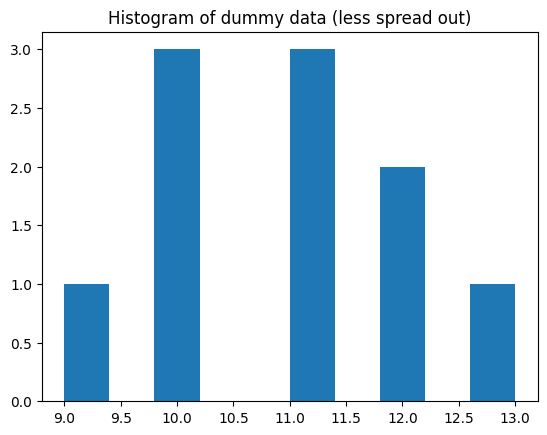

In [ ]:
plt.hist(dummy_1["data"])
plt.title("Histogram of dummy data (less spread out)")
plt.show()

<ipython-input-46-a0285743c27b>:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dummy_1["data"])


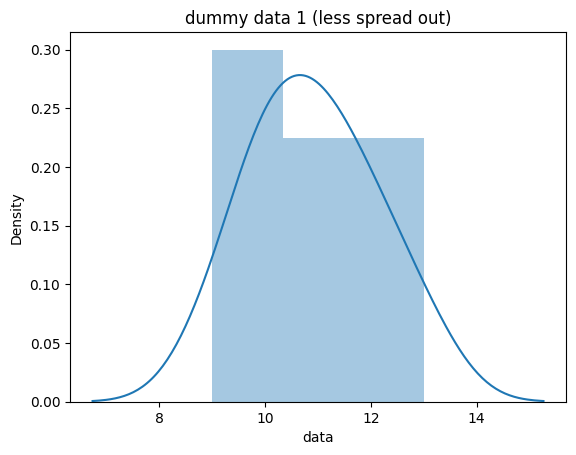

In [ ]:
sns.distplot(dummy_1["data"])
plt.title("dummy data 1 (less spread out)")
plt.show()

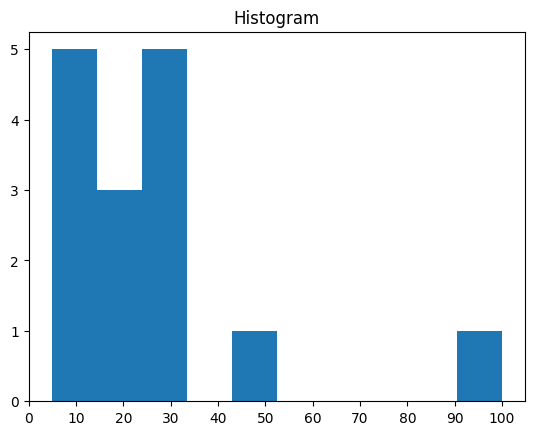

In [ ]:
plt.hist(dummy_2["data"])
plt.title("Histogram")
plt.xticks([0,10,20,30,40,50,60,70,80,90,100])
plt.show()

<ipython-input-64-683d468d2b3e>:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dummy_2["data"])


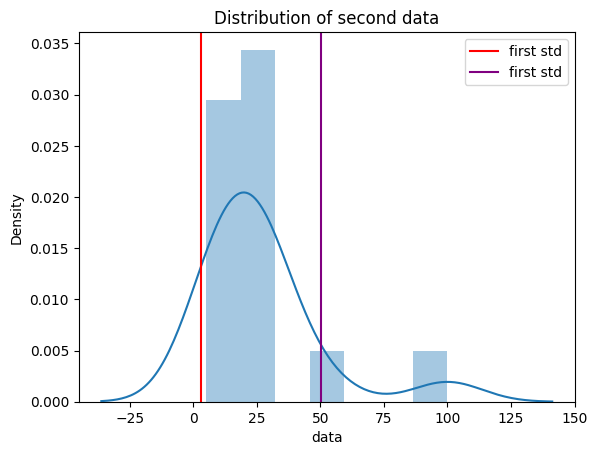

In [ ]:
# distribution
sns.distplot(dummy_2["data"])
plt.title("Distribution of second data")
plt.axvline(lower_first,color="red",label="first std")
plt.axvline(upper_first,color="purple",label="first std")
plt.legend()
plt.show()

In [ ]:
d2_mean = dummy_2["data"].mean()

In [ ]:
std_d2 = dummy_2["data"].std()

In [ ]:
lower_first = d2_mean - std_d2
upper_first = d2_mean + std_d2
lower_second = d2_mean - (std_d2 *2)
upper_second = d2_mean + (std_d2 *2)
lower_third = d2_mean - (std_d2 * 3)
upper_third = d2_mean + (std_d2 * 3)

In [ ]:
d2_mean

26.466666666666665

In [ ]:
upper_first

50.082238607554274